# NN_L12_llm_var

**LLM-VaR after Pele et al. (2026) with an open 3B model: the 5 and 1 percent Value-at-Risk of the S&P 500 written by Qwen2.5-3B-Instruct from the last 250 daily returns, against historical simulation and GARCH(1,1)-t, with Kupiec tests, 2025-2026.**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_llm_var/NN_L12_llm_var.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

llm violations at 05 = 28   [llmvar.llm_05.viol]
llm Kupiec p at 05 = 0.295   [llmvar.llm_05.kupiec_p]
llm violations at 01 = 4   [llmvar.llm_01.viol]
llm Kupiec p at 01 = 0.777   [llmvar.llm_01.kupiec_p]
hs violations at 05 = 23   [llmvar.hs_05.viol]
hs Kupiec p at 05 = 0.991   [llmvar.hs_05.kupiec_p]
hs violations at 01 = 6   [llmvar.hs_01.viol]
hs Kupiec p at 01 = 0.528   [llmvar.hs_01.kupiec_p]
garch violations at 05 = 35   [llmvar.garch_05.viol]
garch Kupiec p at 05 = 0.016   [llmvar.garch_05.kupiec_p]
garch violations at 01 = 9   [llmvar.garch_01.viol]
garch Kupiec p at 01 = 0.067   [llmvar.garch_01.kupiec_p]


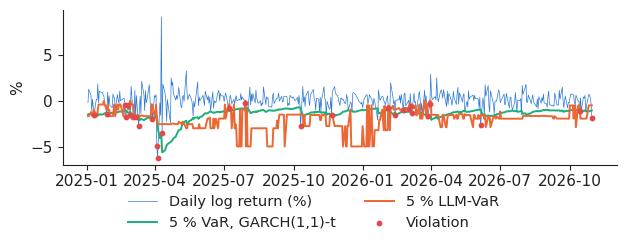

In [3]:
RES = REPO + 'lectures/L12/results/'
import json, urllib.request
def load_json(name):
    p = RES + name
    return json.load(open(p)) if os.path.exists(p) else json.load(urllib.request.urlopen(p))
from scipy import stats
V = pd.read_csv(RES + 'llmvar_sp500.csv', parse_dates=['date']).set_index('date')
def kupiec(h, a):
    n, x = len(h), int(h.sum()); p = x / n
    lr = -2 * n * np.log(1 - a) if x == 0 else -2 * ((n - x) * np.log(1 - a) + x * np.log(a) - (n - x) * np.log(1 - p) - x * np.log(p))
    return float(1 - stats.chi2.cdf(lr, 1))
for m in ('llm', 'hs', 'garch'):
    for a, s in ((0.05, '05'), (0.01, '01')):
        h = (V['r'] < V[f'{m}_{s}']).values
        show(f'llmvar.{m}_{s}.viol', f'{m} violations at {s}', int(h.sum()))
        show(f'llmvar.{m}_{s}.kupiec_p', f'{m} Kupiec p at {s}', round(kupiec(h, a), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.5))
ax.plot(V.index, V.r, color=PAL['data'], lw=0.5, label='Daily log return (%)')
ax.plot(V.index, V.garch_05, color=PAL['benchmark'], label='5 % VaR, GARCH(1,1)-t')
ax.plot(V.index, V.llm_05, color=PAL['model'], label='5 % LLM-VaR')
hit = V.r < V.llm_05
ax.scatter(V.index[hit], V.r[hit], s=10, color=PAL['positive'], zorder=3, label='Violation')
ax.set_ylabel('%')
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.15, 1, 1))
fig.savefig('llm_var.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()